# Modern physics vocabulary: English, math, science, and decisions

Every term from Knight Ch. 36–42 (PHYS 106), in four columns:

| Column | Question it answers |
|---|---|
| **English** | What does the word mean, in plain words? |
| **Math** | What is the equation (if any)? Every equation here is **checked for dimensional consistency** by SymPy. |
| **Science** | Why does it matter? What does it say about nature? |
| **Decide** | When do I use it on a problem, and what's the trap? |

The **Decisions** section turns the Midterm 1 mistakes into rules: given → asked → use → avoid.
A printable copy of everything is generated at `docs/modern_physics_vocab.md`.
The definitions are written for this repo, not copied from the book. Your syllabus decides
which chapters are tested.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from dgs import modern_physics_vocab as V
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 250)
print(f"{len(V.VOCAB)} terms, {sum(1 for t in V.VOCAB if t.equation)} with equations, {len(V.DECISIONS)} decision rules")

112 terms, 48 with equations, 14 decision rules


## 1. The vocabulary, chapter by chapter

In [2]:
def show_equation(t):
    if not t.equation:
        return ""
    syms = {k: sp.Symbol(k) for k in t.units}
    return sp.sympify(t.equation, locals={**syms, "Rational": sp.Rational})

for ch, name in V.CHAPTERS.items():
    terms = V.by_chapter(ch)
    display(Markdown(f"### {'Ch. ' + str(ch) + ': ' if ch else ''}{name} ({len(terms)} terms)"))
    display(pd.DataFrame([(t.term, t.english, t.science, t.decide) for t in terms],
                         columns=["term", "English", "science", "decide"]))

### Ch. 36: Relativity (22 terms)

,term,English,science,decide
0,inertial reference frame,"A viewpoint that is not accelerating, where Newton's first law holds.",All of relativity compares measurements made in two such frames.,First step of any relativity problem: name the two frames.
1,principle of relativity,The laws of physics are the same in every inertial frame.,No experiment can tell which inertial frame is 'really' at rest.,Use to argue both observers are equally right.
2,speed of light postulate,Every inertial observer measures light at the same speed c.,Forces time and space to depend on the observer.,"If a result gives a speed above c, something is wrong."
3,event,"Something that happens at one place at one instant: (x, t).","Relativity compares the coordinates of events, not of objects.","List the events (start, end) before computing anything."
4,simultaneity,Two events happening at the same time in a given frame.,Simultaneity is frame-dependent: events simultaneous in one frame are not in another.,Question asks 'simultaneous for the moving observer?' -> use the Lorentz transform of ...
5,relativity of simultaneity,Separated events that are simultaneous in one frame are not simultaneous in a frame mo...,The event ahead (in the direction of motion) happens first for the moving observer.,dt = 0 and dx != 0 in one frame -> dt' = -gamma v dx / c^2.
6,Lorentz factor,"The stretch factor gamma, always >= 1.",gamma = 1 at rest and grows without bound as v -> c.,Compute it first in every relativity problem; remember the SQUARE in v^2/c^2.
7,beta,Speed as a fraction of the speed of light.,Keeps relativity formulas dimensionless.,Write speeds as beta*c to keep the algebra clean.
8,proper time,Time between two events measured by a clock present at both events (same place in that...,Proper time is the shortest time any observer measures between those events.,Ask: which frame sees both events at the same place? That clock reads proper time.
9,time dilation,Moving clocks run slow as seen by an observer they move past.,Explains muons reaching the ground (the comic on the exam cover).,"Given proper time, find another frame's time -> multiply by gamma."


### Ch. 37: Foundations of modern physics (13 terms)

,term,English,science,decide
0,cathode rays,"Beams from the negative electrode of an evacuated tube, later identified as electrons.",Led to the discovery of the electron.,History question context.
1,electron,"The light, negatively charged particle in every atom.","Charge -e, mass 9.11e-31 kg.",Use e = 1.60e-19 C and m_e = 9.11e-31 kg.
2,charge-to-mass ratio,"e/m, measured by bending electrons in fields.",Showed electrons are ~2000x lighter than hydrogen ions.,Crossed or deflecting fields with unknown particle -> ratio q/m.
3,velocity selector,Crossed E and B fields that let only one speed through undeflected.,"Balancing forces, not adding fields.","Undeflected charge in crossed fields -> qE = qvB, so v = E/B. Never add E and B (diffe..."
4,elementary charge,"The smallest free charge, e = 1.60e-19 C.",Millikan's oil drops showed charge comes in whole multiples of e.,Charge = N e with N an integer.
5,electron volt,Energy one electron gains crossing 1 V: 1.60e-19 J.,The natural energy unit for atoms.,Charge e through potential V -> energy in eV equals V numerically.
6,nucleus,"The tiny, dense, positive center of an atom.",Rutherford's large-angle scattering proved it exists.,Atomic size ~1e-10 m; nucleus ~1e-15 m.
7,atomic number,"Z, the number of protons.",Determines the element and its chemistry.,Z identifies the element; changes in beta and alpha decay.
8,mass number,"A, the number of protons plus neutrons.",Sets nuclear size and approximate mass in u.,A = Z + N; conserved in decays.
9,isotope,Atoms with the same Z but different numbers of neutrons.,"Same chemistry, different nuclear properties.","Same element symbol, different A."


### Ch. 38: Quantization (22 terms)

,term,English,science,decide
0,photon,A quantum (smallest packet) of light energy.,Light is absorbed and emitted one photon at a time.,Counting light energy -> number of photons x energy per photon.
1,photon energy,"Energy of one photon, set by its frequency.",Higher frequency (bluer) photons carry more energy.,"Given wavelength, use E = hc/lambda: convert to frequency first, NEVER h times lambda."
2,photon energy from wavelength,Same energy written with wavelength.,hc = 1240 eV*nm is the fast shortcut.,"Given lambda in nm, E(eV) = 1240 / lambda(nm)."
3,Planck's constant,"h = 6.63e-34 J*s, the scale of quantum effects.",Sets how big a quantum of energy is.,Units J*s; hbar = h / (2 pi).
4,photoelectric effect,Light knocking electrons out of a metal.,Showed light comes in photons: one photon frees one electron.,"Light + metal + electrons -> Einstein's equation, not the hydrogen formula."
5,work function,Minimum energy needed to free an electron from a metal.,"A property of the metal, always positive.",phi = hf - e*V_stop. A negative phi means a mistake (often lambda used in place of f).
6,stopping potential,Reverse voltage that just stops the fastest photoelectrons.,Measures the maximum kinetic energy directly.,e*V_stop = K_max. Make sure the voltage given is the STOPPING one.
7,Einstein's photoelectric equation,Photon energy = work function + maximum kinetic energy.,"Energy conservation, one photon at a time.","Given any two of f (or lambda), phi, K_max -> the third."
8,threshold frequency,Lowest frequency that can eject electrons.,"Below it, no electrons no matter how bright the light.",f0 = phi/h; light with f < f0 does nothing.
9,photon momentum,Momentum carried by one photon.,"Light pushes (radiation pressure, Compton scattering).",Photon recoil or radiation pressure.


### Ch. 39: Wave functions and uncertainty (6 terms)

,term,English,science,decide
0,wave function,psi(x): the quantum description of a particle.,Its square gives probabilities; psi itself is not directly measured.,"Asked 'where is the particle likely?' -> look at |psi|^2, not psi."
1,probability density,|psi|^2: probability per unit length.,Large where the particle is likely to be found.,Probability in a small interval = |psi|^2 times the width.
2,normalization,The total probability of finding the particle somewhere is 1.,Fixes the constant in front of psi.,Unknown amplitude A -> set the integral of |psi|^2 equal to 1.
3,wave packet,A short burst of wave made by adding many frequencies.,Models a localized particle.,Short in time or space means broad in frequency or wavelength.
4,bandwidth relation,Duration times frequency spread is about 1.,Classical root of the uncertainty principle.,Pulse of duration dt -> needs frequencies spread over about 1/dt.
5,Heisenberg uncertainty principle,Position and momentum can't both be known exactly.,"A property of waves, not of clumsy measurement.",Confined to size dx -> momentum spread at least hbar/(2 dx). (Some texts use a rougher...


### Ch. 40: One-dimensional quantum mechanics (17 terms)

,term,English,science,decide
0,Schrodinger equation,The equation that determines psi for a given potential energy.,Plays the role Newton's law plays classically.,"Given U(x), the allowed E and psi come from solving it with boundary conditions."
1,potential-energy function,U(x): how potential energy depends on position.,It defines the quantum model (Knight 40.2).,"Identify U(x) first: box, well, parabola, barrier."
2,energy diagram,Graph of U(x) with each allowed energy drawn as a horizontal line.,Most questions can be read off it.,"Spectra, turning points, tunneling and node counts all come from the diagram."
3,classically forbidden region,Where E < U: impossible classically.,Quantum psi decays there but is not zero.,Use the penetration distance eta.
4,turning point,Where E = U: a classical particle stops and turns around.,Boundary between allowed and forbidden regions.,Set E = U(x) and solve for x.
5,boundary conditions,Requirements psi must meet at walls and edges.,They are what quantize the energy.,Rigid wall -> psi = 0 there; finite step -> psi and psi' continuous.
6,quantum number,The integer n labeling allowed states.,n = 1 is the ground state in Knight's convention.,Knight starts at n = 1 even for the oscillator.
7,particle in a rigid box,A particle trapped between infinitely high walls.,Simplest quantized system; models quantum dots.,Infinite walls -> E_n grows as n^2 and shrinks as 1/L^2.
8,zero-point energy,The lowest allowed energy is not zero.,A confined particle can never be at rest (uncertainty).,Ground-state energy E_1 > 0.
9,node,"A point where psi = 0, so the particle is never found there.",psi_n has n - 1 nodes.,Count nodes to identify n.


### Ch. 41: Atomic physics (12 terms)

,term,English,science,decide
0,principal quantum number,"n = 1, 2, 3, ...: sets the shell and mostly the energy.",Shell size grows with n.,Energy level label.
1,orbital quantum number,l = 0 ... n - 1: sets the orbital angular momentum.,"s, p, d, f = l of 0, 1, 2, 3.",Angular momentum magnitude L = sqrt(l(l+1)) hbar.
2,magnetic quantum number,m = -l ... +l: the z-component of angular momentum.,Gives 2l + 1 orientations.,L_z = m hbar.
3,electron spin,Intrinsic angular momentum of the electron: spin up or down.,Stern-Gerlach experiment; doubles the states per orbital.,m_s = +1/2 or -1/2.
4,Pauli exclusion principle,No two electrons in an atom share all four quantum numbers.,Builds the periodic table and makes matter rigid.,Count electrons per subshell: 2(2l + 1).
5,shell and subshell,Shell = same n; subshell = same n and l.,Electron configurations fill subshells in order of energy.,1s 2s 2p 3s 3p 4s 3d ...
6,electron configuration,"List of occupied subshells, e.g. 1s2 2s2 2p6.",Explains chemical behavior.,"Fill lowest energy first, max 2(2l + 1) per subshell."
7,selection rule,Photon transitions require delta l = +/- 1.,A photon carries one unit of angular momentum.,Allowed vs forbidden spectral lines.
8,excited-state lifetime,Average time before an excited atom decays.,Typical ~1e-8 s for allowed transitions.,Number still excited falls exponentially.
9,stimulated emission,A photon triggers an excited atom to emit an identical photon.,The physics behind the laser.,"Same frequency, phase and direction as the trigger photon."


### Ch. 42: Nuclear physics (14 terms)

,term,English,science,decide
0,nucleon,A proton or neutron.,The building blocks of nuclei.,A counts nucleons.
1,nuclide,A specific nucleus with given Z and A.,Written as a symbol with A and Z.,Balance A and Z in every reaction.
2,atomic mass unit,"u = 1/12 the mass of carbon-12, 1.66e-27 kg (931.5 MeV/c^2).",Convenient unit for nuclear masses.,931.5 MeV per u of mass converts to energy.
3,nuclear radius,"Nuclei have radius ~ r0 A^(1/3), r0 ~ 1.2 fm.",Constant density: volume proportional to A.,Size from mass number.
4,strong force,Short-range attraction between nucleons.,Overcomes proton repulsion inside the nucleus.,Range ~1e-15 m.
5,binding energy,Energy needed to pull a nucleus apart into its nucleons.,Comes from the mass defect: the nucleus weighs less than its parts.,Use atomic masses (hydrogen-atom mass for protons) so electrons cancel.
6,binding energy per nucleon,Binding energy divided by A.,Peaks near iron: fusion of light and fission of heavy nuclei both release energy.,Compare stability across nuclei.
7,radioactivity,Spontaneous decay of unstable nuclei.,"Random for each nucleus, predictable on average.",Decay laws are statistical.
8,alpha decay,Emission of a helium-4 nucleus.,"A drops by 4, Z by 2; happens by tunneling.",Balance A and Z.
9,beta decay,"A neutron becomes a proton (beta-minus) or the reverse (beta-plus), emitting an electr...","A unchanged, Z changes by 1.",Balance charge and A.


### Math words (6 terms)

,term,English,science,decide
0,exponential decay,A quantity that falls by the same fraction in each equal time.,"Decay, RC circuits, tunneling all follow it.",Take ln of both sides to solve for time.
1,natural logarithm,"ln, the inverse of e^x.",Turns exponential equations into linear ones.,ln(e^a) = a; ln(1/q) = -ln q.
2,complex number,a + i b with i^2 = -1.,Wave functions are complex; |psi|^2 = psi* psi is real.,Probability uses the magnitude squared.
3,dimensionless,A number with no units.,"Arguments of exp, sin, log must be dimensionless.",Check units of every exponent: a unit inside exp is a mistake.
4,binomial approximation,(1 + x)^n ~ 1 + n x for small x.,Shows relativity reduces to Newton at low speed.,Small parameter (like v/c) -> expand.
5,eigenvalue,A special value (like an allowed energy) for which an equation has a solution.,Allowed energies are eigenvalues of the Schrodinger equation.,Computers find them with a matrix solver.


## 2. The math, with dimension checks

Each equation is shown in SymPy, with the SI unit of every symbol, and checked: both sides
must have the same dimensions, terms added together must match, and the inside of exp, sin,
and log must be dimensionless.

In [3]:
rows = []
for t in V.VOCAB:
    if t.equation:
        ok = V.check_dimensions(t)
        rows.append((t.chapter, t.term, sp.sstr(show_equation(t)), ", ".join(f"{k} [{v}]" for k, v in t.units.items()), "consistent" if ok else "FAIL"))
display(pd.DataFrame(rows, columns=["ch", "term", "equation", "units", "dimension check"]))
print("all consistent:", all(r[-1] == "consistent" for r in rows))

,ch,term,equation,units,dimension check
0,36,speed of light postulate,"Eq(c, d/t)","c [m/s], d [m], t [s]",consistent
1,36,relativity of simultaneity,"Eq(dtp, gamma*(dt - dx*v/c**2))","dtp [s], gamma [1], dt [s], v [m/s], dx [m], c [m/s]",consistent
2,36,Lorentz factor,"Eq(gamma, 1/sqrt(1 - v**2/c**2))","gamma [1], v [m/s], c [m/s]",consistent
3,36,beta,"Eq(beta, v/c)","beta [1], v [m/s], c [m/s]",consistent
4,36,time dilation,"Eq(dt, dtau*gamma)","dt [s], gamma [1], dtau [s]",consistent
5,36,length contraction,"Eq(L, L0/gamma)","L [m], L0 [m], gamma [1]",consistent
6,36,Lorentz transformation,"Eq(xp, gamma*(-t*v + x))","xp [m], gamma [1], x [m], v [m/s], t [s]",consistent
7,36,spacetime interval,"Eq(s2, c**2*dt**2 - dx**2)","s2 [m**2], c [m/s], dt [s], dx [m]",consistent
8,36,relativistic velocity addition,"Eq(up, (u - v)/(1 - u*v/c**2))","up [m/s], u [m/s], v [m/s], c [m/s]",consistent
9,36,relativistic momentum,"Eq(p, gamma*m*v)","p [kg*m/s], gamma [1], m [kg], v [m/s]",consistent


all consistent: True


**photon energy**: Energy of one photon, set by its frequency.

**relativistic velocity addition**: How a velocity measured in one frame looks in another frame.

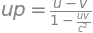

**penetration distance**: How far psi reaches into a forbidden region.

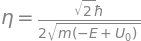

In [4]:
for name in ("photon energy", "relativistic velocity addition", "penetration distance"):
    t = V.lookup(name)[0]
    display(Markdown(f"**{t.term}**: {t.english}")); display(show_equation(t))

## 3. The checker catches real mistakes

These are the errors from Midterm 1 (and two classics), written as equations. Every one fails.

In [5]:
planted = [
    ("Midterm Q2.2: E = h * lambda", "Eq(E, h*lam)", {"E": "J", "h": "J*s", "lam": "m"}),
    ("Midterm Q3.3: v from E + B", "Eq(v, Ef + B)", {"v": "m/s", "Ef": "V/m", "B": "T"}),
    ("units inside an exponential", "Eq(Ptun, exp(-2*w))", {"Ptun": "1", "w": "m"}),
    ("kinetic energy as m v", "Eq(K, m*v)", {"K": "J", "m": "kg", "v": "m/s"}),
]
rows = []
for label, eq, units in planted:
    try:
        V.check_dimensions(V.Term(label, 0, "", "", "", eq, units)); rows.append((label, "NOT caught"))
    except ValueError as err:
        rows.append((label, "caught: " + str(err).split(": ", 1)[1][:90]))
display(pd.DataFrame(rows, columns=["mistake", "result"]))

,mistake,result
0,Midterm Q2.2: E = h * lambda,"caught: E = h * lambda: left side {Dimension(mass): 1, Dimension(length): 2, Dimension..."
1,Midterm Q3.3: v from E + B,"caught: v from E + B: Dimension of ""volt*Ef_val/meter"" is Dimension(voltage/length), b..."
2,units inside an exponential,"caught: argument of exp has units {Dimension(length, L): 1}: must be dimensionless"
3,kinetic energy as m v,"caught: left side {Dimension(mass): 1, Dimension(length): 2, Dimension(time): -2} != r..."


## 4. Decisions: given → asked → use → avoid

In [6]:
display(pd.DataFrame(V.DECISIONS).drop(columns="keywords"))

,given,asked,use,avoid
0,photon wavelength,photon energy or frequency,f = c/lambda; E = h f = hc/lambda (E[eV] = 1240/lambda[nm]),h times lambda (wrong units); the hydrogen formula
1,"light on a metal, stopping potential","work function, K_max, or v_max",K_max = e V_stop; phi = hf - K_max; v = sqrt(2 K_max / m),negative work function; the hydrogen formula; using a voltage that is not the stopping...
2,an atom's energy levels or a diagram,emitted or absorbed wavelengths,lambda = hc / |E_i - E_f| for each allowed pair,-13.6/n^2 unless the atom is hydrogen
3,events simultaneous in one frame,are they simultaneous for a moving observer?,dt' = gamma (dt - v dx / c^2),the spacetime interval (it is the same in all frames)
4,a length measured in the object's rest frame,length seen by a moving observer,L = L0 / gamma (shorter),dropping the square in gamma; getting a longer length
5,a clock's own (proper) time,time in another frame,dt = gamma dtau (longer),dividing by gamma
6,two velocities in different frames,velocity in the other frame,u' = (u - v)/(1 - u v / c^2) with signs,Galilean u - v; ignoring direction
7,a fast particle (K comparable to m c^2),"energy, momentum, or speed","gamma, E = gamma m c^2, E^2 = (pc)^2 + (mc^2)^2",(1/2) m v^2 at high speed
8,a particle's kinetic energy or speed,de Broglie wavelength,p = sqrt(2 m K) (slow) or relativistic p; lambda = h / p,using the photon formula E = hc/lambda for a massive particle
9,a potential-energy shape,allowed energies or wave functions,"box: n^2; finite well: lower, finite count; parabola: (n - 1/2) hbar omega",mixing up the box and oscillator formulas


In [7]:
questions = [
    "A photon has a wavelength of 178 nm. Find its energy in eV.",
    "Light hits a metal and the stopping potential is 5.7 V. Find the work function.",
    "Two eruptions are simultaneous on Earth. Are they simultaneous for the moving observer?",
    "A rock moves toward the ship at 0.4c; find the velocity of the rock relative to the ship.",
    "A 10 eV electron hits the atom. Use the energy diagram to find the emitted wavelengths.",
    "A charge passes undeflected through crossed electric and magnetic fields. Find v.",
]
for q in questions:
    best = V.decide(q)
    print(f"Q: {q}")
    if best:
        r = best[0][1]
        print(f"   use:   {r['use']}\n   avoid: {r['avoid']}\n")

Q: A photon has a wavelength of 178 nm. Find its energy in eV.
   use:   f = c/lambda; E = h f = hc/lambda (E[eV] = 1240/lambda[nm])
   avoid: h times lambda (wrong units); the hydrogen formula

Q: Light hits a metal and the stopping potential is 5.7 V. Find the work function.
   use:   K_max = e V_stop; phi = hf - K_max; v = sqrt(2 K_max / m)
   avoid: negative work function; the hydrogen formula; using a voltage that is not the stopping potential

Q: Two eruptions are simultaneous on Earth. Are they simultaneous for the moving observer?
   use:   dt' = gamma (dt - v dx / c^2)
   avoid: the spacetime interval (it is the same in all frames)

Q: A rock moves toward the ship at 0.4c; find the velocity of the rock relative to the ship.
   use:   u' = (u - v)/(1 - u v / c^2) with signs
   avoid: Galilean u - v; ignoring direction

Q: A 10 eV electron hits the atom. Use the energy diagram to find the emitted wavelengths.
   use:   lambda = hc / |E_i - E_f| for each allowed pair
   avoid: -1

## 5. Flashcards

Read the term, say the English, math, science, and decision out loud, then run the next cell
to check yourself. Change `seed` for a new deck and `chapter` to focus on one chapter.

In [8]:
deck = V.flashcards(chapter=None, n=8, seed=2026)
for i, card in enumerate(deck, 1):
    print(f"{i}. {card.term}   (Ch. {card.chapter})")

1. relativistic velocity addition   (Ch. 36)
2. work function   (Ch. 38)
3. potential-energy function   (Ch. 40)
4. energy diagram   (Ch. 40)
5. magnetic quantum number   (Ch. 41)
6. binomial approximation   (Ch. 0)
7. spacetime interval   (Ch. 36)
8. nucleus   (Ch. 37)


In [9]:
for i, card in enumerate(deck, 1):
    eq = f"\n   math:    {sp.sstr(show_equation(card))}" if card.equation else ""
    print(f"{i}. {card.term}\n   english: {card.english}{eq}\n   science: {card.science}\n   decide:  {card.decide}\n")

1. relativistic velocity addition
   english: How a velocity measured in one frame looks in another frame.
   math:    Eq(up, (u - v)/(1 - u*v/c**2))
   science: Keeps every speed below c.
   decide:  Plug in velocities WITH signs (left = negative); check |u'| < c and that it makes sense.

2. work function
   english: Minimum energy needed to free an electron from a metal.
   math:    Eq(phi, -Vs*e + f*h)
   science: A property of the metal, always positive.
   decide:  phi = hf - e*V_stop. A negative phi means a mistake (often lambda used in place of f).

3. potential-energy function
   english: U(x): how potential energy depends on position.
   science: It defines the quantum model (Knight 40.2).
   decide:  Identify U(x) first: box, well, parabola, barrier.

4. energy diagram
   english: Graph of U(x) with each allowed energy drawn as a horizontal line.
   science: Most questions can be read off it.
   decide:  Spectra, turning points, tunneling and node counts all come from the dia

## 6. Coverage and the printable sheet

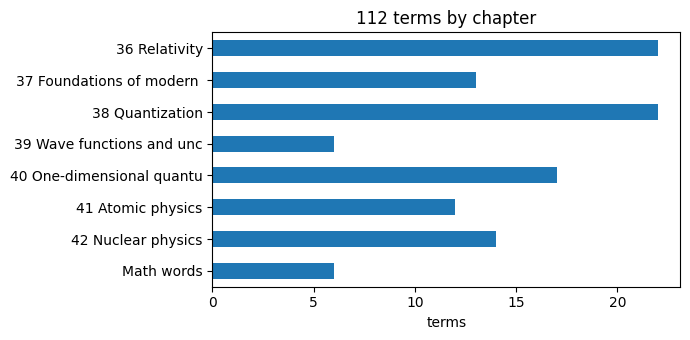

printable study sheet: D:\Summer2026\Dispersion-Assisted-GS-Phase-Recovery\.claude\worktrees\phys106-midterm-sympy-lean-c8e910\docs\modern_physics_vocab.md exists: True


In [10]:
counts = pd.Series({f"{ch} {name[:22]}" if ch else name: len(V.by_chapter(ch)) for ch, name in V.CHAPTERS.items()})
ax = counts.plot.barh(figsize=(7, 3.5), color="C0"); ax.set_xlabel("terms"); ax.invert_yaxis()
ax.set_title(f"{len(V.VOCAB)} terms by chapter"); plt.tight_layout(); plt.show()
sheet = Path.cwd().parent / "docs" / "modern_physics_vocab.md" if Path.cwd().name == "notebooks" else Path("docs/modern_physics_vocab.md")
print("printable study sheet:", sheet, "exists:", sheet.exists())